In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install torch torchvision scikit-learn joblib matplotlib


In [ ]:
# copy the zip from Drive into the Colab VM
!cp /content/drive/MyDrive/uwndc19/uwndc19.zip /content/
# unzip it into /content/uwndc19
!unzip -q /content/uwndc19.zip -d /content/uwndc19


replace /content/uwndc19/spike_data.nc? [y]es, [n]o, [A]ll, [N]one, [r]ename: [n]o
error:  invalid response [[n]o]
replace /content/uwndc19/spike_data.nc? [y]es, [n]o, [A]ll, [N]one, [r]ename: [n]o
error:  invalid response [[n]o]
replace /content/uwndc19/spike_data.nc? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace /content/uwndc19/stim.npy? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace /content/uwndc19/stim_wpos_dva.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace /content/uwndc19/sub.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace /content/uwndc19/train.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no


In [ ]:
!pip install netCDF4


In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from netCDF4 import Dataset as NCFile

# 1) Dataset loader with NaN/Inf cleanup
class UWNDCDataset(Dataset):
    def __init__(self, data_dir):
        ds = NCFile(os.path.join(data_dir, 'spike_data.nc'), 'r')
        raw = ds.variables['resp'][:]
        ds.close()
        clean = np.nan_to_num(raw, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
        stim = np.load(os.path.join(data_dir, 'stim.npy'))
        n = min(len(clean), len(stim))
        self.spikes = clean[:n]

    def __len__(self):
        return len(self.spikes)

    def __getitem__(self, idx):
        return torch.from_numpy(self.spikes[idx]).float()

# 2) DataLoader
dataset = UWNDCDataset('/content/uwndc19')
loader  = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=2)

# 3) Determine flat_dim and define Autoencoder
sample_batch = next(iter(loader))
flat_dim     = sample_batch.numel() // sample_batch.size(0)
print("Per-example feature length:", flat_dim)

class ConvAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, input_dim),
            nn.Sigmoid()
        )
    def forward(self, x):
        x_flat     = x.view(x.size(0), -1)
        z          = self.encoder(x_flat)
        recon_flat = self.decoder(z)
        return recon_flat.view_as(x), z

# 4) Instantiate model & optimizer
autoenc   = ConvAutoencoder(input_dim=flat_dim, latent_dim=32)
optimizer = torch.optim.Adam(autoenc.parameters(), lr=1e-5)
autoenc.train()

# 5) Training loop (10 epochs)
for epoch in range(1, 11):
    total_loss = 0.0
    for x in loader:
        recon, _ = autoenc(x)
        loss = F.mse_loss(recon, x)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(autoenc.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    print(f"Epoch {epoch}/10 - Recon Loss: {total_loss/len(dataset):.6f}")


Per-example feature length: 244800
Epoch 1/10 - Recon Loss: 0.250644
Epoch 2/10 - Recon Loss: 0.250573
Epoch 3/10 - Recon Loss: 0.250491
Epoch 4/10 - Recon Loss: 0.250379
Epoch 5/10 - Recon Loss: 0.250233
Epoch 6/10 - Recon Loss: 0.250051
Epoch 7/10 - Recon Loss: 0.249832
Epoch 8/10 - Recon Loss: 0.249572
Epoch 9/10 - Recon Loss: 0.249267
Epoch 10/10 - Recon Loss: 0.248914


Reconstruction error mean: 0.248700
Reconstruction error std:  0.000056


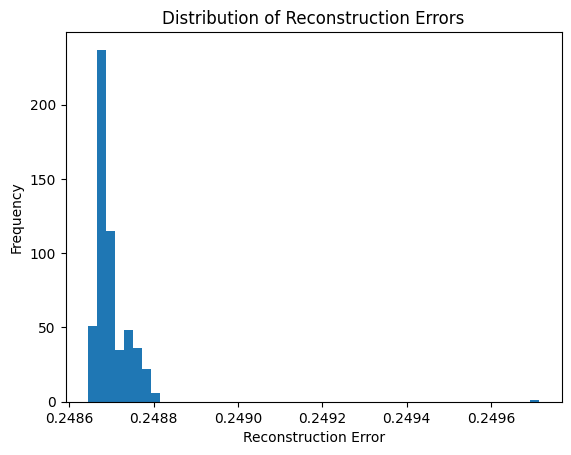

Anomaly threshold: 0.248867
Number of anomalies detected: 1 out of 551 samples
Example anomaly indices: [242]


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

autoenc.eval()
errors = []
with torch.no_grad():
    for x in loader:
        recon, _ = autoenc(x)
        # Mean squared error per sample
        batch_err = ((recon - x) ** 2).view(x.size(0), -1).mean(dim=1)
        errors.append(batch_err.cpu())

# Concatenate all errors
errors = torch.cat(errors).numpy()

# Print basic stats
print(f"Reconstruction error mean: {errors.mean():.6f}")
print(f"Reconstruction error std:  {errors.std():.6f}")

# Plot histogram of reconstruction errors
plt.figure()
plt.hist(errors, bins=50)
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.title('Distribution of Reconstruction Errors')
plt.show()

# Flag anomalies above mean + 3*std
threshold = errors.mean() + 3 * errors.std()
anomaly_indices = np.where(errors > threshold)[0]
print(f"Anomaly threshold: {threshold:.6f}")
print(f"Number of anomalies detected: {len(anomaly_indices)} out of {len(errors)} samples")
print("Example anomaly indices:", anomaly_indices[:10])


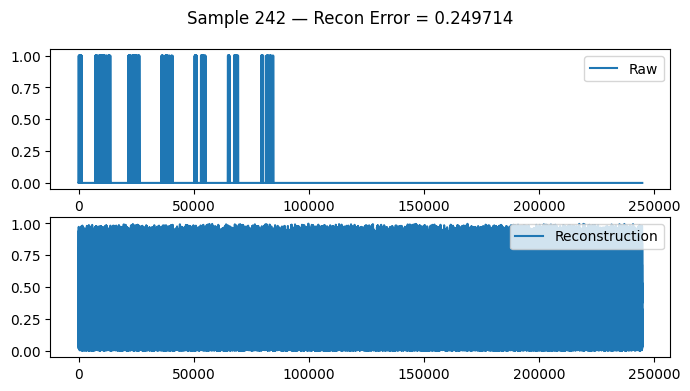

In [ ]:
# In Colab, after training:
idx = 242
x = dataset[idx]                          # raw spikes: shape [17,18,800]
with torch.no_grad():
    recon, _ = autoenc(x.unsqueeze(0))    # recon shape [1,17,18,800]
recon = recon.squeeze(0).numpy()

# Plot a few channels or time‐slices
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,1, figsize=(8,4))
axes[0].plot(x.flatten(), label='Raw')
axes[1].plot(recon.flatten(), label='Reconstruction')
axes[0].legend(); axes[1].legend()
plt.suptitle(f'Sample {idx} — Recon Error = {errors[idx]:.6f}')
plt.show()


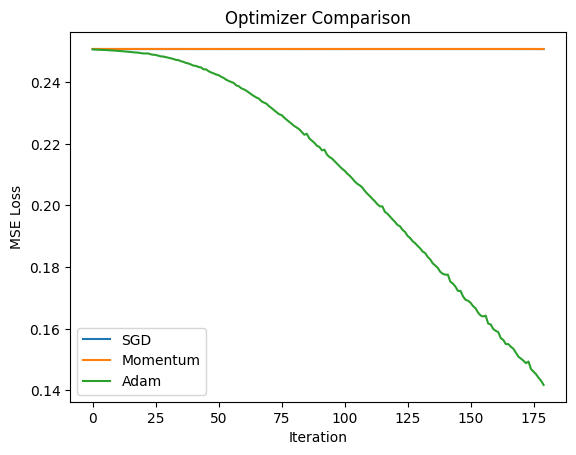

In [ ]:
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

optimizers = {
    'SGD': torch.optim.SGD(autoenc.parameters(), lr=1e-3),
    'Momentum': torch.optim.SGD(autoenc.parameters(), lr=1e-3, momentum=0.9),
    'Adam': torch.optim.Adam(autoenc.parameters(), lr=1e-4)
}
losses = {name: [] for name in optimizers}

for name, opt in optimizers.items():
    # reinitialize weights
    autoenc.apply(lambda m: m.reset_parameters() if hasattr(m, 'reset_parameters') else None)
    for epoch in range(10):
        for x in loader:
            recon, _ = autoenc(x)
            loss = F.mse_loss(recon, x)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses[name].append(loss.item())

plt.figure()
for name, vals in losses.items():
    plt.plot(vals, label=name)
plt.xlabel('Iteration')
plt.ylabel('MSE Loss')
plt.title('Optimizer Comparison')
plt.legend()
plt.show()


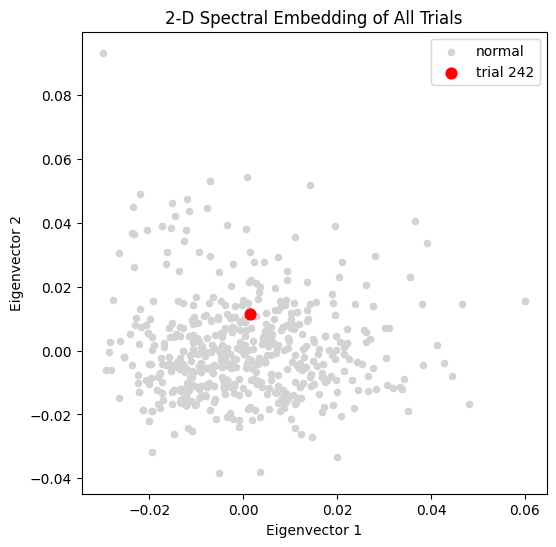

In [ ]:
from sklearn.manifold import SpectralEmbedding
import matplotlib.pyplot as plt

# Get the raw spikes array from your dataset
spikes_np = dataset.spikes             # shape [551, 17, 18, 800]

# Flatten each trial to a vector of length 17*18*800 = 244800
X = spikes_np.reshape(len(spikes_np), -1)

# Compute a 2-D spectral embedding (Laplacian Eigenmap)
embed = SpectralEmbedding(n_components=2, n_neighbors=10, eigen_solver='arpack')
Z = embed.fit_transform(X)  # shape [551,2]

# Plot, highlighting trial 242
plt.figure(figsize=(6,6))
plt.scatter(Z[:,0], Z[:,1], c='lightgray', s=20, label='normal')
plt.scatter(Z[242,0], Z[242,1], c='red',       s=60, label='trial 242')
plt.title('2-D Spectral Embedding of All Trials')
plt.legend()
plt.xlabel('Eigenvector 1')
plt.ylabel('Eigenvector 2')
plt.show()


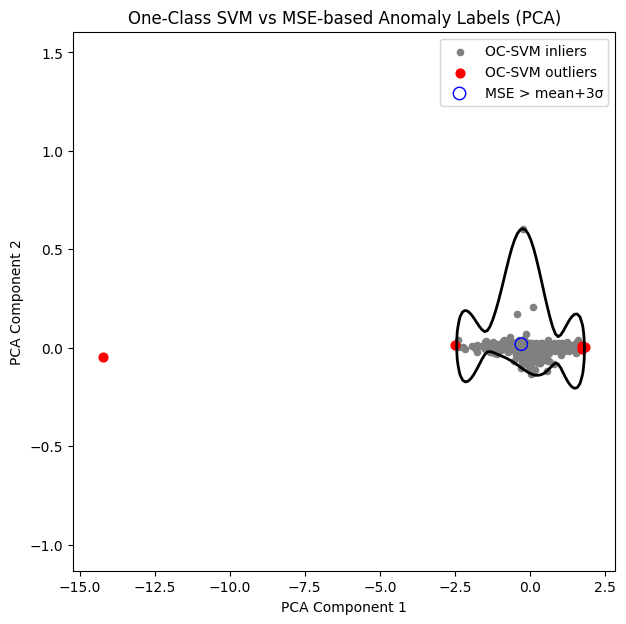

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
import torch

# 1) Recompute latent codes for all trials
latent_codes = []
autoenc.eval()
with torch.no_grad():
    for x in loader:
        _, z = autoenc(x)
        latent_codes.append(z.cpu().numpy())
latent_codes = np.vstack(latent_codes)  # shape [551, latent_dim]

# 2) Fit One-Class SVM on the latent codes
ocsvm = OneClassSVM(nu=0.01, kernel='rbf', gamma='scale')
ocsvm.fit(latent_codes)

# 3) Project codes to 2D via PCA for visualization
pca = PCA(n_components=2)
Z2 = pca.fit_transform(latent_codes)    # shape [551, 2]

# 4) Generate a grid over PCA space to plot the SVM decision boundary
x_min, x_max = Z2[:,0].min() - 1, Z2[:,0].max() + 1
y_min, y_max = Z2[:,1].min() - 1, Z2[:,1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Fit a fresh One-Class SVM on the 2D PCA projections
ocsvm2 = OneClassSVM(nu=0.01, kernel='rbf', gamma='scale').fit(Z2)
grid_vals = ocsvm2.decision_function(np.c_[xx.ravel(), yy.ravel()])
grid_vals = grid_vals.reshape(xx.shape)

# 5) Determine MSE-based anomalies
def compute_errors(model, data_loader):
    errs = []
    with torch.no_grad():
        for x in data_loader:
            recon, _ = model(x)
            batch_err = ((recon - x)**2).view(x.size(0), -1).mean(dim=1)
            errs.append(batch_err.cpu().numpy())
    return np.concatenate(errs)

errors = compute_errors(autoenc, loader)
threshold = errors.mean() + 3 * errors.std()
mse_outliers = errors > threshold

# 6) Plot everything
plt.figure(figsize=(7,7))
# SVM decision boundary (level = 0)
plt.contour(xx, yy, grid_vals, levels=[0], colors='black', linewidths=2)

# OC-SVM inliers vs outliers
inliers = ocsvm.predict(latent_codes) == 1
plt.scatter(Z2[inliers,0], Z2[inliers,1], c='gray', s=20, label='OC-SVM inliers')
plt.scatter(Z2[~inliers,0], Z2[~inliers,1], c='red', s=40, label='OC-SVM outliers')

# MSE-based anomalies
plt.scatter(Z2[mse_outliers,0], Z2[mse_outliers,1],
            facecolors='none', edgecolors='blue', s=80,
            label='MSE > mean+3σ')

plt.title('One-Class SVM vs MSE-based Anomaly Labels (PCA)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()
